# Les événements de masse

Un **événement de masse**, c'est un moment où les défaillances **sortent nettement de la normale** : une chute ou une vague d'un coup, pour tout le pays, pour un secteur, pour un département, ou même un seul jour dans un tribunal. L'idée est de les repérer de façon systématique, puis de les mettre en évidence.

### Comment on mesure « la normale »

Les défaillances ont des saisons (beaucoup moins en août, par exemple). On compare donc chaque mois au **même mois des années 2010 à 2019** (la moyenne des dix), la décennie avant le Covid. Ça donne un **indice** :
- **100** = un mois normal ;
- **50** = deux fois moins de défaillances que d'habitude ;
- **200** = deux fois plus.

### Lexique

| Terme | En clair |
|---|---|
| **Indice** | Le nombre de défaillances du mois, divisé par la moyenne du même mois en 2010-2019, × 100. |
| **Épisode** | Une suite de mois consécutifs anormaux (au-dessus ou en dessous des seuils). |
| **Journée de masse** | Un jour où un seul tribunal prononce un nombre inhabituel d'entrées en défaillance. |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Référence | Le **même mois de 2010-2019** (moyenne sur dix ans). Avec 2017-2019 seulement, la normale était trop basse (les défaillances baissaient depuis 2015) : presque tous les mois paraissaient au-dessus. Avec 2010-2019, l'indice médian vaut 100. | Luka |
| Mois anormal (national) | Indice **sous 75** (au moins 25 % de défaillances en moins) ou **au-dessus de 125** (au moins 25 % en plus). Deux mois anormaux qui se suivent forment un épisode. | Luka |
| Pic local (secteur, département) | Un mois avec au moins **3 fois** la normale, au moins **30** défaillances, et une normale d'au moins **10** défaillances (sinon, un mois d'août où le tribunal siège peu donne des rapports absurdes, comme × 96). | Luka |
| Journée de masse | Au moins **50** entrées en défaillance le même jour dans le même tribunal (99 % des journées en ont moins de 31). | Luka |

## 1. Chargement

In [1]:
import sys
sys.path.append("../../scripts")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from data_utils import PROCESSED, RAW, NAF_DIVISIONS
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
FAITS = PROCESSED / "cube_faits.parquet"
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 60)
con = duckdb.connect()
con.execute("SET memory_limit = '3GB'")

def sql(q):
    return con.execute(q).df()

noms_dep, _ = gu.charger_departements(RAW / "geo" / "departements.geojson")

## 2. Au niveau national : les mois anormaux

In [2]:
mensuel = sql(f"""
    SELECT mois, count(*) AS entrees FROM read_parquet('{FAITS}')
    WHERE categorie = 'entrée en défaillance' AND mois BETWEEN '2008-01' AND '2026-10'
    GROUP BY mois ORDER BY mois""").set_index("mois")
mensuel["mois_annee"] = mensuel.index.str[5:]
ANNEES_REF = [str(a) for a in range(2010, 2020)]
ref = mensuel[mensuel.index.str[:4].isin(ANNEES_REF)].groupby("mois_annee")["entrees"].mean()
mensuel["reference"] = mensuel["mois_annee"].map(ref)
mensuel["indice"] = 100 * mensuel["entrees"] / mensuel["reference"]
mensuel["anormal"] = np.select([mensuel["indice"] < 75, mensuel["indice"] > 125], ["chute", "vague"], "")
mensuel[["entrees", "reference", "indice"]].describe().round(1)

,entrees,reference,indice
count,226.0,226.0,226.0
mean,4488.8,4708.5,95.1
std,1350.7,979.0,20.4
min,670.0,1741.4,26.5
25%,3977.0,4553.6,88.3
50%,4869.0,5072.8,99.6
75%,5452.5,5343.2,108.8
max,6541.0,5484.5,129.6


In [3]:
# Les épisodes : au moins 2 mois anormaux consécutifs dans le même sens
m = mensuel.reset_index()
m["bloc"] = (m["anormal"] != m["anormal"].shift()).cumsum()
episodes = (m[m["anormal"] != ""].groupby("bloc")
            .agg(type=("anormal", "first"), debut=("mois", "first"), fin=("mois", "last"), mois=("mois", "size"),
                 indice_moyen=("indice", "mean"), indice_extreme=("indice", lambda s: s.min() if s.mean() < 100 else s.max()),
                 defaillances=("entrees", "sum"), normale=("reference", "sum")))
episodes = episodes[episodes["mois"] >= 2].reset_index(drop=True)
episodes["écart à la normale"] = episodes["defaillances"] - episodes["normale"]
episodes.round(0)

,type,debut,fin,mois,indice_moyen,indice_extreme,defaillances,normale,écart à la normale
0,chute,2020-01,2022-08,32,54.0,27.0,81089,149344.0,-68255.0


### Observations

- Avec la référence 2010-2019, il n'y a qu'**un seul épisode** national : la **chute du Covid**, de **janvier 2020 à août 2022** (32 mois). L'indice moyen y est de **54** : presque deux fois moins de défaillances que d'habitude.
- Sur ces 32 mois, on compte **81 089** entrées en défaillance au lieu des **149 344** attendues : environ **68 000 défaillances « manquantes »**.
- Janvier 2020 est déjà un peu sous la normale (indice 74), avant le premier confinement (mars 2020).

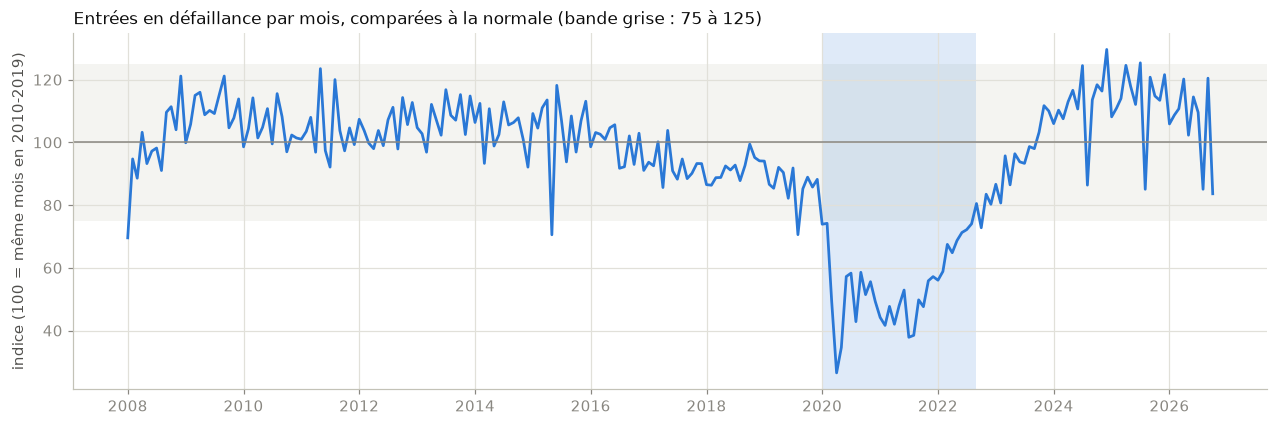

In [4]:
fig, ax = plt.subplots(figsize=(14, 4.2))
dates = pd.to_datetime(mensuel.index)
ax.plot(dates, mensuel["indice"], color=gu.BLEU, lw=1.8)
ax.axhline(100, color=gu.GRIS, lw=1)
ax.axhspan(75, 125, color="#e1e0d9", alpha=0.35, lw=0)
for _, e in episodes.iterrows():
    couleur = gu.COULEURS[0] if e["type"] == "chute" else gu.COULEURS[1]
    ax.axvspan(pd.Timestamp(e["debut"]), pd.Timestamp(e["fin"]) + pd.offsets.MonthEnd(0), color=couleur, alpha=0.15, lw=0)
ax.set_ylabel("indice (100 = même mois en 2010-2019)")
ax.set_title("Entrées en défaillance par mois, comparées à la normale (bande grise : 75 à 125)", loc="left",
             fontsize=11, color=gu.TITRE)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

### Observations

- Avant le Covid, l'indice reste presque toujours dans la bande normale. Il baisse doucement de 2015 à 2019 (les défaillances diminuaient).
- La chute est brutale : l'indice tombe à **27** en avril 2020, pendant le premier confinement.
- La remontée est lente : l'indice ne revient à 100 qu'en **2023**, puis passe **au-dessus** en 2024-2025.

In [5]:
# L'indice moyen de chaque année
display(mensuel.groupby(mensuel.index.str[:4])["indice"].mean().round(0).rename("indice moyen").to_frame().T)
# Les mois les plus extrêmes
pd.concat([mensuel.nsmallest(5, "indice"), mensuel.nlargest(5, "indice")])[["entrees", "reference", "indice"]].round(0)

mois,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
indice moyen,98.0,111.0,105.0,104.0,105.0,108.0,104.0,104.0,99.0,93.0,91.0,87.0,53.0,47.0,71.0,96.0,113.0,114.0,106.0


,entrees,reference,indice
mois,,,
2020-04,1207,4554.0,27.0
2020-05,1562,4516.0,35.0
2021-07,1725,4557.0,38.0
2021-08,670,1741.0,38.0
2021-02,2126,5107.0,42.0
2024-12,5580,4305.0,130.0
2025-07,5713,4557.0,125.0
2025-04,5672,4554.0,125.0
2024-07,5673,4557.0,124.0


### Observations

- En moyenne, **2024** (113) et **2025** (114) sont les années les plus hautes de la période, devant **2009** (111), l'année de la crise financière. Mais l'écart reste modéré : c'est un niveau un peu au-dessus des années 2010, pas un choc comparable à la chute du Covid.
- Le mois le plus haut est **décembre 2024** (indice 130). Les mois les plus bas sont tous en 2020 et 2021.

## 3. Les pics par secteur et par département

Même calcul, mais pour chaque secteur (division NAF) et chaque département : on cherche les mois avec **au moins 3 fois** la normale, **au moins 30** défaillances, et une normale d'au moins 10.

In [6]:
def pics(colonne, minimum_total=500):
    t = sql(f"""
        SELECT {colonne} AS cle, mois, count(*) AS entrees FROM read_parquet('{FAITS}')
        WHERE categorie = 'entrée en défaillance' AND {colonne} <> 'non renseigné' AND mois BETWEEN '2008-01' AND '2026-10'
        GROUP BY ALL""")
    total = t.groupby("cle")["entrees"].sum()
    t = t[t["cle"].isin(total.index[total >= minimum_total])]
    complet = t.pivot_table(index="mois", columns="cle", values="entrees", fill_value=0)
    ref = complet[complet.index.str[:4].isin(ANNEES_REF)]
    ref = ref.groupby(ref.index.str[5:]).mean()
    attendu = pd.DataFrame(ref.loc[complet.index.str[5:]].to_numpy(), index=complet.index, columns=complet.columns)
    ratio = complet / attendu.where(attendu > 0)
    p = (pd.DataFrame({"entrees": complet.stack(), "normale": attendu.stack(), "ratio": ratio.stack()})
           .dropna().reset_index())
    return p[(p["ratio"] >= 3) & (p["entrees"] >= 30) & (p["normale"] >= 10)].sort_values("ratio", ascending=False)

pics_sect = pics("naf_division")
pics_sect["secteur"] = pics_sect["cle"].map(NAF_DIVISIONS)
print(len(pics_sect), "pics sectoriels")
pics_sect.head(15).round(1)

16 pics sectoriels


,mois,cle,entrees,normale,ratio,secteur
13014,2025-06,88,81.0,14.8,5.5,Action sociale sans hébergement
11820,2023-11,66,70.0,17.7,4.0,Auxiliaires de services financiers et d'assurance
12068,2024-03,66,65.0,17.8,3.7,Auxiliaires de services financiers et d'assurance
11882,2023-12,66,59.0,16.2,3.6,Auxiliaires de services financiers et d'assurance
12812,2025-03,66,62.0,17.8,3.5,Auxiliaires de services financiers et d'assurance
12006,2024-02,66,61.0,17.6,3.5,Auxiliaires de services financiers et d'assurance
13556,2026-03,66,61.0,17.8,3.4,Auxiliaires de services financiers et d'assurance
13060,2025-07,66,56.0,16.6,3.4,Auxiliaires de services financiers et d'assurance
12874,2025-04,66,51.0,16.0,3.2,Auxiliaires de services financiers et d'assurance
13494,2026-02,66,56.0,17.6,3.2,Auxiliaires de services financiers et d'assurance


In [7]:
# Ces pics tombent-ils pendant les épisodes nationaux ?
pics_sect["annee"] = pics_sect["mois"].str[:4]
pics_sect.groupby("annee").size().rename("pics sectoriels").to_frame().T

annee,2023,2024,2025,2026
pics sectoriels,3,5,4,4


### Observations

- On trouve **16 pics sectoriels**, et **tous depuis fin 2023** : il n'y en a aucun avant, même en 2009.
- Presque tous concernent un seul secteur : les **auxiliaires de services financiers et d'assurance** (courtiers, intermédiaires…). Depuis novembre 2023, ce secteur a, mois après mois, **3 à 4 fois** plus de défaillances que d'habitude. Ce n'est pas un pic isolé, mais une **vague durable**.
- L'autre pic est l'**action sociale sans hébergement** en juin 2025 (81 défaillances au lieu de 15).

In [8]:
pics_dep = pics("departement")
pics_dep["département"] = pics_dep["cle"].map(lambda d: noms_dep.get(d, d))
print(len(pics_dep), "pics départementaux")
pics_dep.head(15).round(1)

8 pics départementaux


,mois,cle,entrees,normale,ratio,département
22523,2026-10,80,142.0,30.1,4.7,Somme
1717,2009-06,22,121.0,29.1,4.2,Côtes-d'Armor
5965,2012-12,80,156.0,39.3,4.0,Somme
21048,2025-07,974,119.0,32.3,3.7,La Réunion
3195,2010-09,05,74.0,20.3,3.6,Hautes-Alpes
19851,2024-07,974,109.0,32.3,3.4,La Réunion
19629,2024-05,77,278.0,87.0,3.2,Seine-et-Marne
21154,2025-09,09,32.0,10.4,3.1,Ariège


### Observations

- On trouve **8 pics départementaux**, souvent liés à une seule journée de masse dans un tribunal (voir la section 4) : la **Somme** (décembre 2012 et octobre 2026), les **Côtes-d'Armor** (juin 2009), la **Seine-et-Marne** (mai 2024), **La Réunion** (juillet 2024 et juillet 2025).

## 4. Les journées de masse

Un seul tribunal, un seul jour, des dizaines d'entreprises : souvent un **groupe de sociétés** jugé en une fois, ou un tribunal qui traite d'un coup un grand nombre de dossiers. On décrit chaque journée : secteur principal, part de liquidations, part d'entreprises citées dans une même annonce (annonce collective).

In [9]:
jours = sql(f"""
    SELECT date_evenement::DATE AS jour, tribunal, departement, count(*) AS entrees,
           avg(CASE WHEN nature ILIKE '%liquidation%' THEN 1.0 ELSE 0 END) AS part_liquidation,
           avg(CASE WHEN annonce_collective THEN 1.0 ELSE 0 END) AS part_collective,
           mode(naf_division) AS division
    FROM read_parquet('{FAITS}') WHERE categorie = 'entrée en défaillance'
    GROUP BY ALL HAVING count(*) >= 50 ORDER BY entrees DESC""")
part_div = sql(f"""
    SELECT date_evenement::DATE AS jour, tribunal, naf_division AS division, count(*) AS n
    FROM read_parquet('{FAITS}') WHERE categorie = 'entrée en défaillance' GROUP BY ALL""")
jours = jours.merge(part_div, on=["jour", "tribunal", "division"], how="left")
jours["part du secteur principal"] = jours["n"] / jours["entrees"]
jours["secteur principal"] = jours["division"].map(lambda d: NAF_DIVISIONS.get(d, d))
jours = jours.drop(columns=["n"])
print(len(jours), "journées de masse (au moins 50 entrées le même jour dans le même tribunal)")
jours.head(15).round({"part_liquidation": 2, "part_collective": 2, "part du secteur principal": 2})

111 journées de masse (au moins 50 entrées le même jour dans le même tribunal)


,jour,tribunal,departement,entrees,part_liquidation,part_collective,division,part du secteur principal,secteur principal
0,2024-12-11,TRIBUNAL DE COMMERCE - LYON,69,190,0.98,0.0,41,0.93,Construction de bâtiments
1,2026-04-22,TRIBUNAL DE COMMERCE - LYON,69,147,0.99,0.0,41,0.86,Construction de bâtiments
2,2018-10-04,TRIBUNAL DE COMMERCE - PARIS,75,131,0.89,0.0,non renseigné,0.79,non renseigné
3,2025-07-09,TRIBUNAL DE COMMERCE - CRETEIL,94,129,0.97,0.0,43,0.35,Travaux de construction spécialisés
4,2012-12-10,TRIBUNAL JUDICIAIRE - AMIENS,80,122,1.00,0.0,non renseigné,1.00,non renseigné
5,2024-05-13,TRIBUNAL DE COMMERCE - MEAUX,77,117,0.32,0.0,47,0.61,Commerce de détail
6,2025-06-30,TRIBUNAL DE COMMERCE - EVRY,91,99,0.28,0.0,88,0.58,Action sociale sans hébergement
7,2026-04-20,TRIBUNAL DE COMMERCE - EVRY,91,93,0.91,0.0,43,0.22,Travaux de construction spécialisés
8,2009-06-16,TRIBUNAL JUDICIAIRE - SAINT-BRIEUC,22,90,0.03,0.0,41,0.89,Construction de bâtiments
9,2009-09-10,TRIBUNAL DE COMMERCE - PARIS,75,89,0.18,0.0,non renseigné,0.57,non renseigné


In [10]:
jours["annee"] = pd.to_datetime(jours["jour"]).dt.year
jours.groupby("annee").agg(journees=("entrees", "size"), entrees=("entrees", "sum")).T

annee,2008,2009,2010,2012,2013,2014,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
journees,6,10,5,2,2,6,2,1,3,2,1,1,2,8,22,24,14
entrees,365,617,290,172,111,334,116,51,234,104,64,59,104,465,1490,1466,953


### Observations

- On compte **111 journées de masse** (au moins 50 entrées en défaillance le même jour dans le même tribunal).
- Elles sont devenues **beaucoup plus fréquentes** : 0 à 6 par an de 2011 à 2022, puis **8 en 2023, 22 en 2024, 24 en 2025** et déjà 14 en 2026. Les tribunaux traitent de plus en plus souvent des dizaines de dossiers en une seule audience.
- Aucune de ces journées ne vient d'une **annonce collective** (part = 0) : ce sont des jugements séparés, prononcés le même jour.

In [11]:
# Les journées « concentrées » : plus de la moitié des entreprises dans un seul secteur
concentrees = jours[jours["part du secteur principal"] >= 0.5]
print(len(concentrees), "journées concentrées sur un secteur")
concentrees[["jour", "tribunal", "entrees", "secteur principal", "part du secteur principal", "part_liquidation"]].round(
    {"part du secteur principal": 2, "part_liquidation": 2})

16 journées concentrées sur un secteur


,jour,tribunal,entrees,secteur principal,part du secteur principal,part_liquidation
0,2024-12-11,TRIBUNAL DE COMMERCE - LYON,190,Construction de bâtiments,0.93,0.98
1,2026-04-22,TRIBUNAL DE COMMERCE - LYON,147,Construction de bâtiments,0.86,0.99
2,2018-10-04,TRIBUNAL DE COMMERCE - PARIS,131,non renseigné,0.79,0.89
4,2012-12-10,TRIBUNAL JUDICIAIRE - AMIENS,122,non renseigné,1.00,1.00
5,2024-05-13,TRIBUNAL DE COMMERCE - MEAUX,117,Commerce de détail,0.61,0.32
6,2025-06-30,TRIBUNAL DE COMMERCE - EVRY,99,Action sociale sans hébergement,0.58,0.28
8,2009-06-16,TRIBUNAL JUDICIAIRE - SAINT-BRIEUC,90,Construction de bâtiments,0.89,0.03
9,2009-09-10,TRIBUNAL DE COMMERCE - PARIS,89,non renseigné,0.57,0.18
15,2010-09-10,TRIBUNAL DE COMMERCE - GAP,69,Construction de bâtiments,0.71,0.99
24,2024-02-01,TRIBUNAL DE COMMERCE - PARIS,64,Restauration,0.61,0.36


### Observations

- **16 journées** sont concentrées sur un seul secteur (plus de la moitié des entreprises).
- Les deux plus grandes viennent du **Tribunal de Commerce de Lyon** : **190** entreprises le 11 décembre 2024 et **147** le 22 avril 2026, à **86-93 % dans la construction de bâtiments**, presque toutes liquidées. Ça ressemble à la chute de groupes de promotion immobilière, dont chaque programme est une société à part. C'est une hypothèse : les données ne permettent pas de relier ces entreprises entre elles.
- La construction de bâtiments revient souvent dans ces journées (Saint-Brieuc 2009, Gap 2010, Montpellier 2014, Nantes 2025).
- Dans 10 journées, le secteur est inconnu (« non renseigné ») : souvent des annonces sans SIREN, que l'on ne peut pas relier à SIRENE.

## 5. Le rattrapage, par secteur et par région

Le dashboard permet de filtrer par **secteur** (section NAF) et par **région**. On prépare donc les entrées en défaillance par **mois × secteur × région**. Le dashboard recalcule ensuite, pour le périmètre choisi, la normale, l'indice et le **solde du rattrapage** : la somme, depuis janvier 2020, des écarts entre les défaillances réelles et la normale.

Avant ça, on regarde le solde pour la France entière.

In [12]:
mensuel["ecart"] = mensuel["entrees"] - mensuel["reference"]
solde = mensuel.loc["2020-01":, "ecart"].cumsum()
print(f"déficit pendant l'épisode Covid (2020-01 à 2022-08) : {mensuel.loc['2020-01':'2022-08', 'ecart'].sum():,.0f}".replace(",", " "))
print(f"solde le plus bas : {solde.min():,.0f} ({solde.idxmin()})".replace(",", " "))
print(f"solde fin octobre 2026 : {solde.iloc[-1]:,.0f}".replace(",", " "))
mensuel["ecart"].groupby(mensuel.index.str[:4]).sum().loc["2019":].round(0).rename("écart à la normale").to_frame().T

déficit pendant l'épisode Covid (2020-01 à 2022-08) : -68 255
solde le plus bas : -75 926 (2023-09)
solde fin octobre 2026 : -54 667


mois,2019,2020,2021,2022,2023,2024,2025,2026
écart à la normale,-7013.0,-26130.0,-29708.0,-16622.0,-2264.0,7835.0,8717.0,3503.0


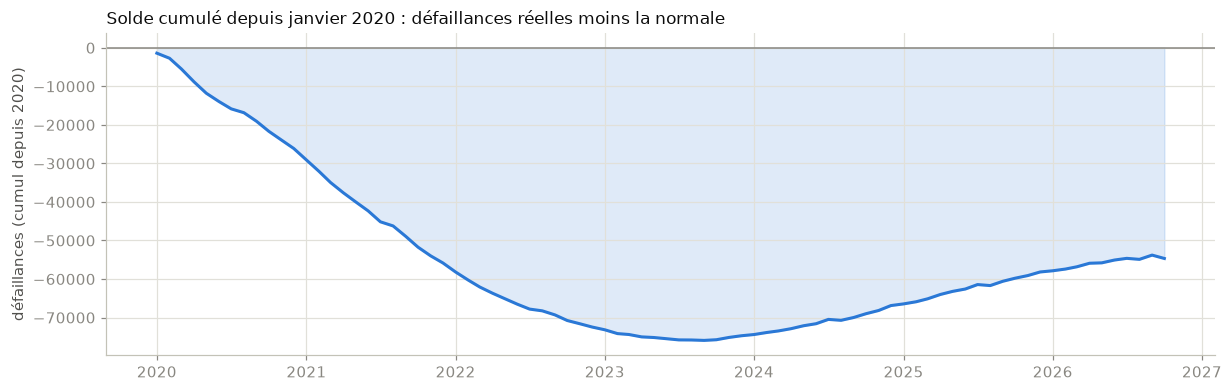

In [13]:
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.fill_between(pd.to_datetime(solde.index), solde.values, 0, color=gu.BLEU, alpha=0.15)
ax.plot(pd.to_datetime(solde.index), solde.values, color=gu.BLEU, lw=2)
ax.axhline(0, color=gu.GRIS, lw=1)
ax.set_ylabel("défaillances (cumul depuis 2020)")
ax.set_title("Solde cumulé depuis janvier 2020 : défaillances réelles moins la normale", loc="left", fontsize=11, color=gu.TITRE)
plt.show()

In [14]:
par_perimetre = sql(f"""
    SELECT mois, naf_section, region, count(*) AS entrees FROM read_parquet('{FAITS}')
    WHERE categorie = 'entrée en défaillance' AND mois BETWEEN '2008-01' AND '2026-10'
    GROUP BY ALL""")
print(par_perimetre.shape, "| total :", par_perimetre["entrees"].sum())
par_perimetre.head()

(54039, 4) | total : 1014462


,mois,naf_section,region,entrees
0,2026-01,C,Occitanie,32
1,2022-11,K,Île-de-France,27
2,2022-02,L,Auvergne-Rhône-Alpes,12
3,2011-11,F,Île-de-France,283
4,2016-09,M,Île-de-France,90


### Observations

- Pendant l'épisode Covid (janvier 2020 à août 2022), il manque **68 255** défaillances par rapport à la normale. Le déficit continue de se creuser après l'épisode : le solde atteint son point le plus bas en **septembre 2023** (**−75 926**).
- Ensuite, les défaillances repassent au-dessus de la normale : **+7 835** en 2024, **+8 717** en 2025, **+3 503** sur les dix premiers mois de 2026.
- Fin octobre 2026, le solde est encore de **−54 667** : sur les quelque 76 000 défaillances « gelées », seulement **21 000** environ ont été rattrapées.
- Les données ne disent pas ce que sont devenues les autres : des entreprises sauvées pour de bon, fermées sans procédure collective, ou un rattrapage encore à venir. C'est une question ouverte.

## 6. Export pour le dashboard

In [15]:
mensuel.reset_index().to_parquet(DASH / "evenements_mensuel.parquet", index=False)
par_perimetre.to_parquet(DASH / "evenements_mensuel_perimetre.parquet", index=False)
episodes.to_parquet(DASH / "evenements_episodes.parquet", index=False)
pics_sect.to_parquet(DASH / "evenements_pics_secteurs.parquet", index=False)
pics_dep.to_parquet(DASH / "evenements_pics_departements.parquet", index=False)
jours.assign(jour=jours["jour"].astype(str)).to_parquet(DASH / "evenements_jours.parquet", index=False)
con.close()
print("export : evenements_mensuel, evenements_episodes, evenements_pics_secteurs, evenements_pics_departements, evenements_jours")

export : evenements_mensuel, evenements_episodes, evenements_pics_secteurs, evenements_pics_departements, evenements_jours
